In [3]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# --------------------------------
# 1. Create sample student dataset
# --------------------------------

np.random.seed(42)

data = {
    "study_hours": np.random.randint(1, 10, 100),
    "attendance": np.random.randint(40, 101, 100),
    "previous_marks": np.random.randint(30, 101, 100),
    "assignments": np.random.randint(1, 11, 100)
}

df = pd.DataFrame(data)

# Generate sample final marks
df["final_marks"] = (
    df["study_hours"] * 3
    + df["attendance"] * 0.2
    + df["previous_marks"] * 0.4
    + df["assignments"] * 1.5
    + np.random.normal(0, 5, 100)
).clip(0, 100)

# --------------------------------
# 2. Prepare input and output
# --------------------------------

X = df[[
    "study_hours",
    "attendance",
    "previous_marks",
    "assignments"
]]

y = df["final_marks"]

# --------------------------------
# 3. Split the dataset
# --------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --------------------------------
# 4. Train Machine Learning model
# --------------------------------

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")

# --------------------------------
# 5. Evaluate the model
# --------------------------------

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
accuracy_score = r2_score(y_test, predictions)

print("\nModel Evaluation")
print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(accuracy_score, 2))

# --------------------------------
# 6. Get new student information
# --------------------------------

print("\nSTUDENT PERFORMANCE PREDICTION")

study_hours = float(input("Enter daily study hours: "))
attendance = float(input("Enter attendance percentage: "))
previous_marks = float(input("Enter previous marks: "))
assignments = float(input("Enter completed assignments (out of 10): "))

# --------------------------------
# 7. Predict student marks
# --------------------------------

new_student = pd.DataFrame([{
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_marks": previous_marks,
    "assignments": assignments
}])

predicted_marks = model.predict(new_student)[0]

predicted_marks = np.clip(predicted_marks, 0, 100)

print("\n------ PREDICTION RESULT ------")

print("Predicted Final Marks:",
      round(predicted_marks, 2))

if predicted_marks >= 75:
    print("Performance: Excellent")
elif predicted_marks >= 60:
    print("Performance: Good")
elif predicted_marks >= 40:
    print("Performance: Average")
else:
    print("Performance: Needs Improvement")

print("--------------------------------")


Model training completed!

Model Evaluation
Mean Absolute Error: 6.13
R2 Score: 0.69

STUDENT PERFORMANCE PREDICTION


Enter daily study hours:  6
Enter attendance percentage:  85.5
Enter previous marks:  75
Enter completed assignments (out of 10):  8



------ PREDICTION RESULT ------
Predicted Final Marks: 76.32
Performance: Excellent
--------------------------------


Creating Food Waste Dataset...
Dataset created successfully!

First 5 records:
     stock_kg  daily_sales_kg  days_to_expiry  demand_index  price_per_kg  \
0   81.162623       21.548528              12             1    261.736440   
1  190.635718       17.010698              14             4    243.718366   
2  149.078849       10.666773               8            10    239.108827   
3  123.745112       24.786261               3             6     98.356950   
4   39.643542       21.172473               8             7     33.466592   

   weekend  actual_waste_kg  
0        0         0.000000  
1        1         2.394589  
2        0        60.988341  
3        1        43.204409  
4        1         0.000000  

Checking missing values:
stock_kg           0
daily_sales_kg     0
days_to_expiry     0
demand_index       0
price_per_kg       0
weekend            0
actual_waste_kg    0
dtype: int64

Training Machine Learning Model...
Model trained successfully!

----- MODEL PERFORMANCE ---

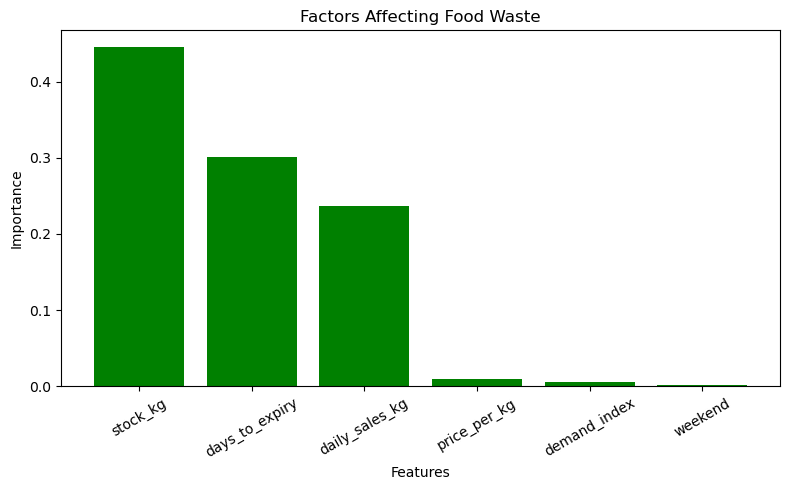


 SMART FOOD WASTE PREDICTION 


Enter available stock (kg):  100
Enter average daily sales (kg):  10
Enter days remaining before expiry:  5
Enter demand index (1-10):  4
Enter price per kg:  50
Is it weekend? (1=Yes, 0=No):  0



========== RESULT ==========
Available Stock: 100.0 kg
Predicted Unsold Food: 34.99 kg
Estimated Waste Percentage: 34.99 %

----- RECOMMENDATION -----
Moderate predicted waste.
Consider promotional offers.

Note: Prediction is an estimate,
not a food safety assessment.


In [6]:

# SMART FOOD WASTE PREDICTION SYSTEM
# Python + Machine Learning Project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

np.random.seed(42)

# =====================================
# 1. CREATE DATASET
# =====================================

print("Creating Food Waste Dataset...")

data_size = 500

stock = np.random.uniform(10, 200, data_size)
sales = np.random.uniform(2, 30, data_size)
expiry = np.random.randint(1, 15, data_size)
demand = np.random.randint(1, 11, data_size)
price = np.random.uniform(10, 300, data_size)
weekend = np.random.randint(0, 2, data_size)

# Expected sales before expiry
expected_sales = sales * expiry

# Estimate unsold quantity
waste = np.maximum(0, stock - expected_sales)

# Add some natural variation
waste = waste + np.random.normal(0, 4, data_size)

# Adjust based on demand and weekend
waste = waste - (demand * 0.5) - (weekend * 2)

# Keep waste within available stock
waste = np.clip(waste, 0, stock)

# Create DataFrame
df = pd.DataFrame({
    "stock_kg": stock,
    "daily_sales_kg": sales,
    "days_to_expiry": expiry,
    "demand_index": demand,
    "price_per_kg": price,
    "weekend": weekend,
    "actual_waste_kg": waste
})

# Save dataset
df.to_csv("food_waste_dataset.csv", index=False)

print("Dataset created successfully!")
print("\nFirst 5 records:")
print(df.head())

# =====================================
# 2. DATA PREPROCESSING
# =====================================

print("\nChecking missing values:")

print(df.isnull().sum())

X = df.drop("actual_waste_kg", axis=1)
y = df["actual_waste_kg"]

# =====================================
# 3. SPLIT DATASET
# =====================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# =====================================
# 4. TRAIN MACHINE LEARNING MODEL
# =====================================

print("\nTraining Machine Learning Model...")

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

# =====================================
# 5. MODEL EVALUATION
# =====================================

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("\n----- MODEL PERFORMANCE -----")

print("Mean Absolute Error:", round(mae, 2), "kg")
print("R2 Score:", round(r2, 3))

# =====================================
# 6. FEATURE IMPORTANCE
# =====================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nImportant Factors:")
print(importance)

plt.figure(figsize=(8, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"],
    color="green"
)

plt.title("Factors Affecting Food Waste")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# =====================================
# 7. FOOD WASTE PREDICTION
# =====================================

print("\n================================")
print(" SMART FOOD WASTE PREDICTION ")
print("================================")

stock_input = float(input("Enter available stock (kg): "))

sales_input = float(input("Enter average daily sales (kg): "))

expiry_input = int(input("Enter days remaining before expiry: "))

demand_input = int(input("Enter demand index (1-10): "))

price_input = float(input("Enter price per kg: "))

weekend_input = int(input("Is it weekend? (1=Yes, 0=No): "))

# Input validation
if (
    stock_input <= 0
    or sales_input < 0
    or expiry_input < 1
    or not 1 <= demand_input <= 10
    or price_input < 0
    or weekend_input not in [0, 1]
):
    print("Invalid input. Please check the values.")

else:

    new_food = pd.DataFrame([{
        "stock_kg": stock_input,
        "daily_sales_kg": sales_input,
        "days_to_expiry": expiry_input,
        "demand_index": demand_input,
        "price_per_kg": price_input,
        "weekend": weekend_input
    }])

    predicted_waste = model.predict(new_food)[0]

    # Predicted waste cannot exceed available stock
    predicted_waste = np.clip(
        predicted_waste, 0, stock_input
    )

    predicted_waste = round(predicted_waste, 2)

    print("\n========== RESULT ==========")

    print("Available Stock:", stock_input, "kg")

    print("Predicted Unsold Food:",
          predicted_waste, "kg")

    waste_percentage = (
        predicted_waste / stock_input
    ) * 100

    print("Estimated Waste Percentage:",
          round(waste_percentage, 2), "%")

    # =================================
    # 8. RECOMMENDATION SYSTEM
    # =================================

    print("\n----- RECOMMENDATION -----")

    if predicted_waste <= 0:
        print("Low predicted waste.")
        print("Continue monitoring inventory.")

    elif expiry_input <= 2:
        print("High priority: Food is nearing expiry.")
        print("Consider immediate discount or donation.")
        print("Donation only if food is safe and legally eligible.")

    elif waste_percentage >= 40:
        print("High predicted waste.")
        print("Consider discounts and donation planning.")

    elif waste_percentage >= 15:
        print("Moderate predicted waste.")
        print("Consider promotional offers.")

    else:
        print("Low predicted waste.")
        print("Monitor stock and sales.")

    print("\nNote: Prediction is an estimate,")
    print("not a food safety assessment.")


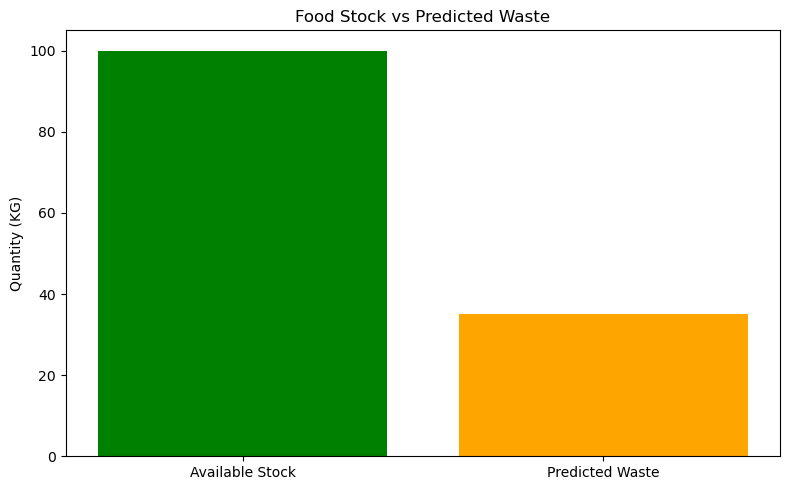

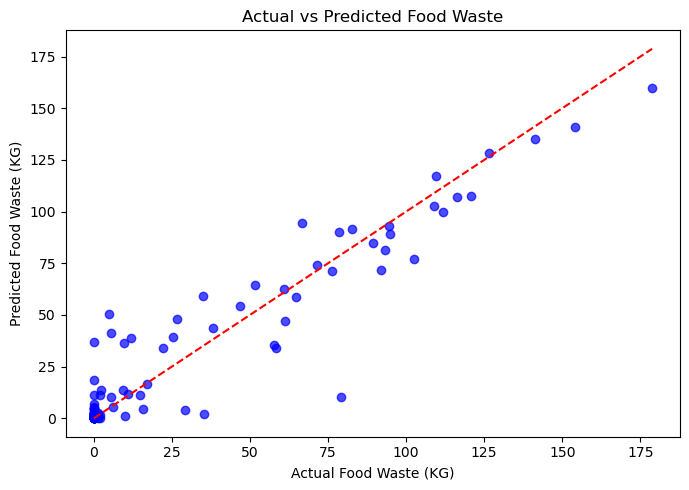

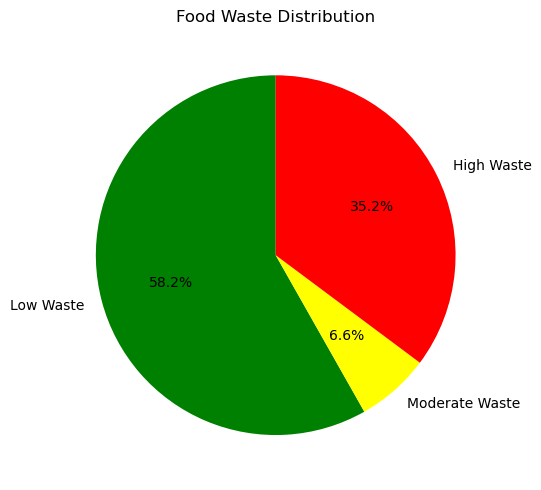

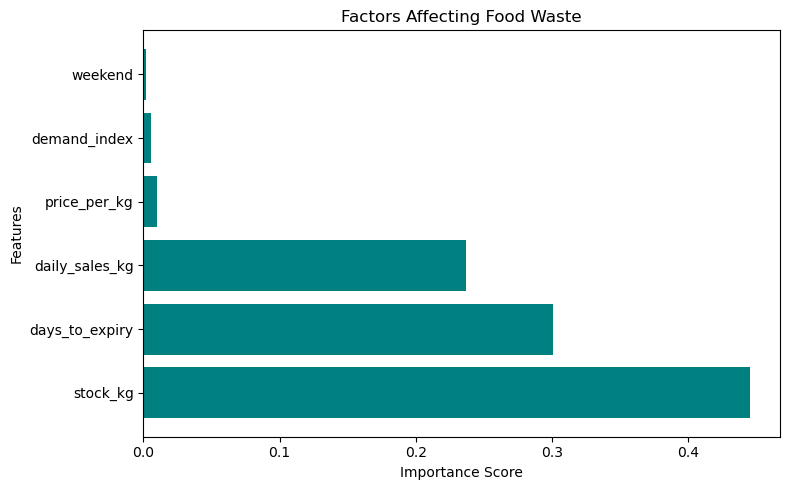

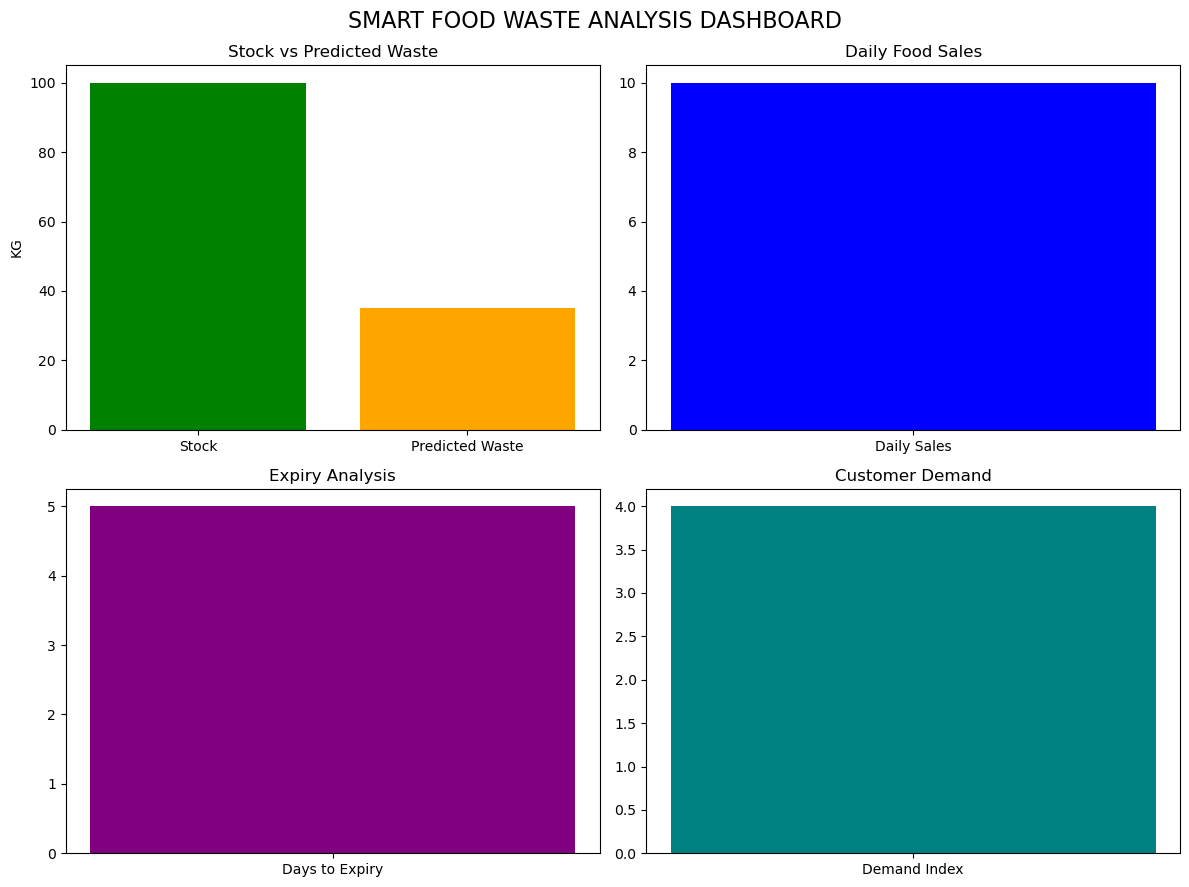

In [7]:

# =========================================
# GRAPH 1: STOCK VS PREDICTED FOOD WASTE
# =========================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Available Stock", "Predicted Waste"],
    [stock_input, predicted_waste],
    color=["green", "orange"]
)

plt.title("Food Stock vs Predicted Waste")
plt.ylabel("Quantity (KG)")

plt.tight_layout()
plt.show()


# =========================================
# GRAPH 2: ACTUAL VS PREDICTED WASTE
# =========================================

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    predictions,
    color="blue",
    alpha=0.7
)

plt.plot(
    [0, max(y_test.max(), predictions.max())],
    [0, max(y_test.max(), predictions.max())],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Food Waste (KG)")
plt.ylabel("Predicted Food Waste (KG)")

plt.title("Actual vs Predicted Food Waste")

plt.tight_layout()
plt.show()


# =========================================
# GRAPH 3: FOOD WASTE DISTRIBUTION
# =========================================

low = (df["actual_waste_kg"] < 10).sum()

moderate = (
    (df["actual_waste_kg"] >= 10) &
    (df["actual_waste_kg"] < 30)
).sum()

high = (df["actual_waste_kg"] >= 30).sum()

plt.figure(figsize=(7, 5))

plt.pie(
    [low, moderate, high],
    labels=["Low Waste", "Moderate Waste", "High Waste"],
    autopct="%1.1f%%",
    colors=["green", "yellow", "red"],
    startangle=90
)

plt.title("Food Waste Distribution")

plt.tight_layout()
plt.show()


# =========================================
# GRAPH 4: FEATURE IMPORTANCE
# =========================================

plt.figure(figsize=(8, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"],
    color="teal"
)

plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.title("Factors Affecting Food Waste")

plt.tight_layout()
plt.show()


# =========================================
# GRAPH 5: FOOD INVENTORY DASHBOARD
# =========================================

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Stock vs waste
axes[0, 0].bar(
    ["Stock", "Predicted Waste"],
    [stock_input, predicted_waste],
    color=["green", "orange"]
)

axes[0, 0].set_title("Stock vs Predicted Waste")
axes[0, 0].set_ylabel("KG")

# Daily sales
axes[0, 1].bar(
    ["Daily Sales"],
    [sales_input],
    color="blue"
)

axes[0, 1].set_title("Daily Food Sales")

# Expiry
axes[1, 0].bar(
    ["Days to Expiry"],
    [expiry_input],
    color="purple"
)

axes[1, 0].set_title("Expiry Analysis")

# Demand
axes[1, 1].bar(
    ["Demand Index"],
    [demand_input],
    color="teal"
)

axes[1, 1].set_title("Customer Demand")

fig.suptitle(
    "SMART FOOD WASTE ANALYSIS DASHBOARD",
    fontsize=16
)

plt.tight_layout()
plt.show()
